In [1]:
# Download with fixed dates for the past 5 years
import yfinance as yf
import pandas as pd
import numpy as np

tickers = ["^GSPC", "GLD"]
START, END = "2021-11-22", "2026-11-21"   # fixed window -> reproducible

prices = yf.download(
    tickers,
    start=START,
    end=END,
    auto_adjust=True,
)["Close"]

empty = prices.columns[prices.isna().all()]
assert empty.empty, f"No data for: {list(empty)}"

returns = prices.pct_change(fill_method=None).dropna()
print(returns.shape)

[                       0%                       ]

[*********************100%***********************]  2 of 2 completed

(1254, 2)


In [2]:
# Volatility and correlation
TRADING_DAYS = 252

# Step 1, daily return:
# rₜ = (Pₜ − Pₜ₋₁) / Pₜ₋₁
# returns = prices.pct_change(fill_method=None).dropna()

# Step 2, mean daily return:
# r̄ = (1/N) · Σₜ rₜ
# Step 3, daily volatility (sample standard deviation, which is what returns.std() computes):
# σ_daily = √[ (1/(N−1)) · Σₜ (rₜ − r̄)² ]
daily_vol = returns.std()

# Step 4, annual volatility:
# σ_annual = σ_daily · √252
annual_vol = daily_vol * np.sqrt(TRADING_DAYS)  # sqrt-of-time scaling

# Step 5, correlation (Pearson):
# Cov(X,Y) = (1/(N−1)) · Σₜ (xₜ − x̄)(yₜ − ȳ)
# ρ = Cov(X,Y) / (σ_X · σ_Y) ρ ∈ [−1, 1]
corr = returns.corr().loc["^GSPC", "GLD"] # full matrix, then the one off-diagonal cell

print("Annual volatility:\n", annual_vol.round(4))
print("Correlation:", round(corr, 3))

Annual volatility:
 Ticker
GLD      0.1933
^GSPC    0.1730
dtype: float64
Correlation: 0.178


In [3]:
# Verification: compute by hand with numpy and compare to pandas
x = returns["^GSPC"].to_numpy()   # S&P daily returns as a plain array
y = returns["GLD"].to_numpy()     # gold daily returns
N = len(x)

# Step 2: r̄ = (1/N) · Σₜ rₜ
x_bar = np.sum(x) / N
y_bar = np.sum(y) / N

# Step 3: σ_daily = √[ (1/(N−1)) · Σₜ (rₜ − r̄)² ]
sigma_x = np.sqrt(np.sum((x - x_bar) ** 2) / (N - 1))
sigma_y = np.sqrt(np.sum((y - y_bar) ** 2) / (N - 1))

# Step 4: σ_annual = σ_daily · √252
sigma_x_annual = sigma_x * np.sqrt(TRADING_DAYS)
sigma_y_annual = sigma_y * np.sqrt(TRADING_DAYS)

# Step 5: Cov(X,Y) = (1/(N−1)) · Σₜ (xₜ − x̄)(yₜ − ȳ)
cov_xy = np.sum((x - x_bar) * (y - y_bar)) / (N - 1)

# ρ = Cov(X,Y) / (σ_X · σ_Y)
rho = cov_xy / (sigma_x * sigma_y)

# Compare with pandas (isclose allows tiny floating-point differences)
assert np.isclose(sigma_x, daily_vol["^GSPC"])
assert np.isclose(sigma_y, daily_vol["GLD"])
assert np.isclose(sigma_x_annual, annual_vol["^GSPC"])
assert np.isclose(sigma_y_annual, annual_vol["GLD"])
assert np.isclose(rho, corr)

print(f"√252 = {np.sqrt(TRADING_DAYS):.4f}")
print(f"σ_daily  S&P: {sigma_x:.6f}         (pandas {daily_vol['^GSPC']:.6f})")
print(f"σ_daily  GLD: {sigma_y:.6f}         (pandas {daily_vol['GLD']:.6f})")
print(f"σ_annual S&P: {sigma_x_annual:.4f}           (pandas {annual_vol['^GSPC']:.4f})")
print(f"σ_annual GLD: {sigma_y_annual:.4f}           (pandas {annual_vol['GLD']:.4f})")
print(f"ρ:            {rho:.6f}         (pandas {corr:.6f})")

√252 = 15.8745
σ_daily  S&P: 0.010899         (pandas 0.010899)
σ_daily  GLD: 0.012176         (pandas 0.012176)
σ_annual S&P: 0.1730           (pandas 0.1730)
σ_annual GLD: 0.1933           (pandas 0.1933)
ρ:            0.178030         (pandas 0.178030)


In [4]:
# 50/50 portfolio

# Step 6, portfolio daily return (weighted sum, one value per day):
# r_p,t = w₁ · r₁,t + w₂ · r₂,t
# In matrix form: r_p = R · w   (R = returns matrix N×2, w = weights 2×1)
w = pd.Series({"^GSPC": 0.5, "GLD": 0.5})   # weights matched by ticker name, not position
port_returns = returns @ w                   # @ = matrix multiplication → N daily values

# Step 7, portfolio volatility, measured directly from its own returns:
# σ_p = std(r_p) · √252
port_vol = port_returns.std() * np.sqrt(TRADING_DAYS)

# Step 8, Markowitz two-asset variance formula (no portfolio returns needed):
# σ²_p = w₁²σ₁² + w₂²σ₂² + 2·w₁·w₂·ρ·σ₁·σ₂
w1, w2 = w["^GSPC"], w["GLD"]
s1, s2 = annual_vol["^GSPC"], annual_vol["GLD"]
port_vol_formula = np.sqrt(w1**2 * s1**2 + w2**2 * s2**2 + 2 * w1 * w2 * corr * s1 * s2)

assert np.isclose(port_vol, port_vol_formula)   # two routes, same answer

print(f"σ_annual S&P:      {s1:.4f}")
print(f"σ_annual GLD:      {s2:.4f}")
print(f"Simple average:    {(s1 + s2) / 2:.4f}")
print(f"50/50 (measured):  {port_vol:.4f}")
print(f"50/50 (formula):   {port_vol_formula:.4f}")

σ_annual S&P:      0.1730
σ_annual GLD:      0.1933
Simple average:    0.1831
50/50 (measured):  0.1407
50/50 (formula):   0.1407


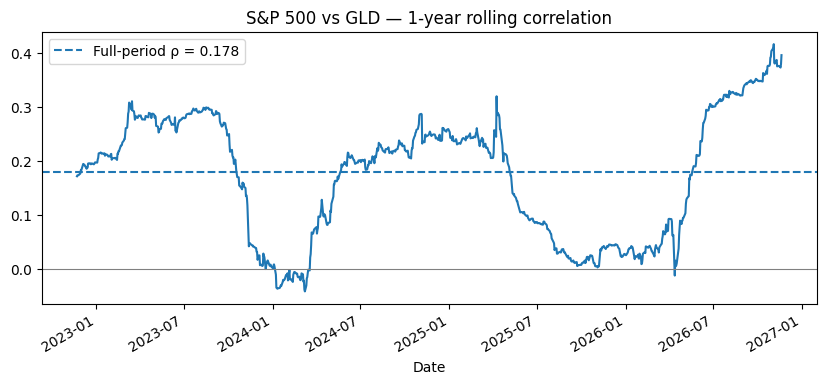

In [5]:
# Step 9, rolling correlation over a 252-day (one-year) window:
# ρₜ = Cov(X,Y) / (σ_X · σ_Y), computed only on days t−251 … t
WINDOW = 252
rolling_corr = returns["^GSPC"].rolling(WINDOW).corr(returns["GLD"])

ax = rolling_corr.plot(title="S&P 500 vs GLD — 1-year rolling correlation", figsize=(10, 4))
ax.axhline(corr, linestyle="--", label=f"Full-period ρ = {corr:.3f}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend()

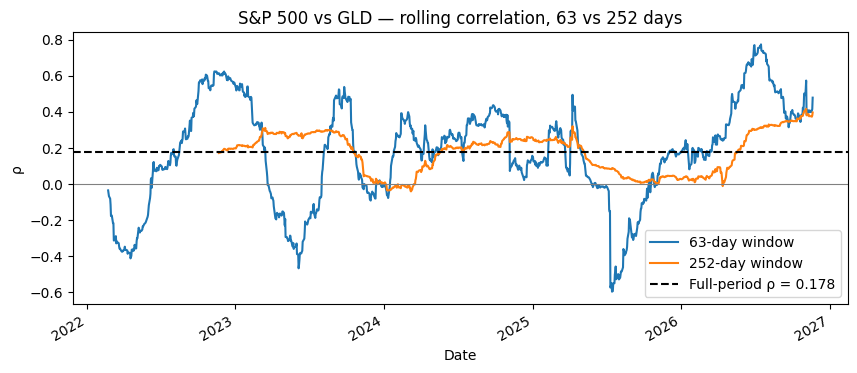

In [6]:
# Step 10, compare window lengths: 63 days (~3 months) vs 252 days (~1 year)
# Same formula as Step 9, ρₜ = Cov(X,Y) / (σ_X · σ_Y), on days t−(W−1) … t
# Shorter window → fewer points per estimate → noisier, but reacts faster
# Sampling error of ρ shrinks roughly as 1/√W
WINDOWS = [63, 252]

ax = None
for W in WINDOWS:
    rc = returns["^GSPC"].rolling(W).corr(returns["GLD"])
    ax = rc.plot(ax=ax, figsize=(10, 4), label=f"{W}-day window")

ax.axhline(corr, linestyle="--", color="black", label=f"Full-period ρ = {corr:.3f}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("S&P 500 vs GLD — rolling correlation, 63 vs 252 days")
ax.set_ylabel("ρ")
ax.legend()

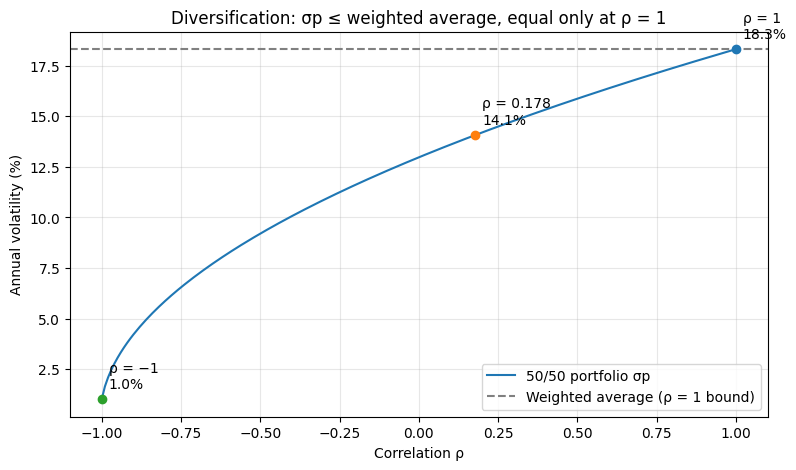

ρ = −1 zero-risk weight: 0.528 S&P / 0.472 gold


In [7]:
# Step 11, volatility vs correlation for the 50/50 portfolio
import matplotlib.pyplot as plt

# Inputs, measured above in Steps 4–5 (annualised)
sigma_A = annual_vol["^GSPC"]   # σA: S&P 500 annual volatility
sigma_B = annual_vol["GLD"]     # σB: GLD annual volatility
rho_real = corr                 # ρ: measured correlation

def portfolio_vol(w, sA, sB, rho):
    # σp² = w²σA² + (1 − w)²σB² + 2·w·(1 − w)·ρ·σA·σB
    var = w**2 * sA**2 + (1 - w)**2 * sB**2 + 2 * w * (1 - w) * rho * sA * sB
    # σp = √σp²
    return np.sqrt(var)

w_5050 = 0.5   # scalar weight; keeps cell 3's weights Series `w` intact
rhos = np.linspace(-1, 1, 201)
vols = portfolio_vol(w_5050, sigma_A, sigma_B, rhos)

# Upper bound (ρ = 1): σp = w·σA + (1 − w)·σB   ← perfect square (a + b)²
avg_vol = w_5050 * sigma_A + (1 - w_5050) * sigma_B

plt.figure(figsize=(9, 5))
plt.plot(rhos, vols * 100, label="50/50 portfolio σp")
plt.axhline(avg_vol * 100, ls="--", c="gray", label="Weighted average (ρ = 1 bound)")
for r, lbl in [(1, "ρ = 1"), (rho_real, f"ρ = {rho_real:.3f}"), (-1, "ρ = −1")]:
    v = portfolio_vol(w_5050, sigma_A, sigma_B, r)
    plt.scatter(r, v * 100, zorder=3)
    plt.annotate(f"{lbl}\n{v*100:.1f}%", (r, v * 100), textcoords="offset points", xytext=(5, 8))
plt.xlabel("Correlation ρ"); plt.ylabel("Annual volatility (%)")
plt.title("Diversification: σp ≤ weighted average, equal only at ρ = 1")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Zero-risk weight at ρ = −1:  w·σA = (1 − w)·σB  →  w* = σB / (σA + σB)
w_star = sigma_B / (sigma_A + sigma_B)
print(f"ρ = −1 zero-risk weight: {w_star:.3f} S&P / {1 - w_star:.3f} gold")

In [8]:
# Step 12, interactive sliders for ρ and w
from ipywidgets import interact, FloatSlider

def explore(rho=rho_real, w=0.5):
    ws = np.linspace(0, 1, 201)
    # Full curve σp(w) for the chosen ρ
    curve = portfolio_vol(ws, sigma_A, sigma_B, rho)
    vp = portfolio_vol(w, sigma_A, sigma_B, rho)
    plt.figure(figsize=(9, 5))
    plt.plot(ws, curve * 100, label=f"σp(w), ρ = {rho:.2f}")
    # Straight line = weighted average, the ρ = 1 case
    plt.plot(ws, (ws * sigma_A + (1 - ws) * sigma_B) * 100, "--", c="gray", label="ρ = 1 line")
    plt.scatter(w, vp * 100, c="red", zorder=3, label=f"w = {w:.2f} → σp = {vp*100:.1f}%")
    plt.xlabel("Weight in S&P 500 (w)"); plt.ylabel("Annual volatility (%)")
    plt.ylim(0, 22); plt.legend(); plt.grid(alpha=0.3); plt.show()

interact(explore,
         rho=FloatSlider(min=-1, max=1, step=0.01, value=rho_real),
         w=FloatSlider(min=0, max=1, step=0.01, value=0.5))

interactive(children=(FloatSlider(value=0.17803029670493187, description='rho', max=1.0, min=-1.0, step=0.01),…

<function __main__.explore(rho=np.float64(0.17803029670493187), w=0.5)>